In [1]:
import sys
from pathlib import Path

import matplotlib_fontja  # noqa: F401

for path in [Path.cwd(), *Path.cwd().parents]:
    if (path / "common" / "notebook_style.py").exists():
        sys.path.insert(0, str(path))
        break

    if (path / "src" / "common" / "notebook_style.py").exists():
        sys.path.insert(0, str(path / "src"))
        break

from common.notebook_style import apply_dataframe_style

apply_dataframe_style()

# 第3章 新製品の普及を予測する


## 第3章、第3節、第1項のコード

### サンプルデータの生成

1採用者が1台を初回購入するという仮定の下で、1ヶ月を1期とする係数 $p = 0.025$、$q = 0.35$、$M = 100{,}000$ を設定値として、離散時間版バスモデルから測定誤差を含む月次販売台数（24ヶ月分）を生成する。最初の10ヶ月を推定用、11〜24ヶ月を検証用として分ける。測定誤差は観測値だけに加え、次の月の計算には誤差を加える前の値を使う。

#### 処理内容

1. **ライブラリのインポート**
   数値計算に使う `NumPy`、データフレームに使う `Polars`、グラフ描画に使う `Matplotlib`、パラメータの推定に使う `scipy.optimize.curve_fit` をインポートする。

2. **データを生成するときの設定値**
   `p_true = 0.025`、`q_true = 0.35`、`M_true = 100_000` をデータを生成するときの設定値とする。

3. **離散時間版バスモデルによるデータ生成**
   差分方程式 $n_t = (p + q \cdot N_{t-1}/M)(M - N_{t-1})$ で各月の新規採用者数を計算し、観測値だけに標準偏差10%の測定誤差を加える。次の月の計算には、誤差を加える前の値を使う。

4. **データフレーム（DataFrame）の整形と累積販売台数の追加**
   `pl.DataFrame` で `period` と `n_sales` の2列を作成し、`cum_sum()` で `N_cum`（累積販売台数）を追加する。`df_observed` に1〜10ヶ月、`df_validation` に11〜24ヶ月を保存する。


In [3]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import polars as pl
from scipy.optimize import curve_fit
from scipy.special import expit, logit

# 1色印刷用のグレースケール設定
MONO_BLACK = "0.00"
MONO_DARK = "0.20"
MONO_MID = "0.50"
MONO_LIGHT = "0.85"


# 再現性のためシード固定
rng = np.random.default_rng(42)

# データを生成するときの設定値
p_true = 0.025
q_true = 0.35
M_true = 100_000

# 離散時間版バスモデルで24ヶ月分のデータを生成
n_total_periods = 24
n_observed = 10
n_sales = []
N_cum_latent = 0.0
for t in range(n_total_periods):
    n_t_latent = (p_true + q_true * N_cum_latent / M_true) * (
        M_true - N_cum_latent
    )
    # 観測値だけに測定誤差を加える（標準偏差：誤差を加える前の値の10%）
    measurement_error = rng.normal(0, n_t_latent * 0.10)
    n_t_observed = max(n_t_latent + measurement_error, 0)
    n_sales.append(int(n_t_observed))
    N_cum_latent += n_t_latent

# Polarsのデータフレームとして整形
df = pl.DataFrame(
    {
        "period": list(range(1, n_total_periods + 1)),
        "n_sales": n_sales,
    }
)
# 累積販売台数を追加
df = df.with_columns(pl.col("n_sales").cum_sum().alias("N_cum"))

# 1〜10ヶ月を推定用、11〜24ヶ月を検証用に分ける
df_observed = df.head(n_observed)
df_validation = df.slice(n_observed)
df.head()

period,n_sales,N_cum
i64,i64,i64
1,2576,2576
2,2948,5524
3,4584,10108
4,5923,16031
5,5384,21415


### 可視化：月次販売台数と累積販売台数の推移

月次販売台数（ベル型）と累積販売台数（S字型）を横並びで描画し、バスモデルの典型的な形状を確認する。

#### 処理内容

1. **月次販売台数の棒グラフ（左図）**
   `axes[0].bar()` で発売後の月次販売台数の推移をベル型として描画する。

2. **累積販売台数の折れ線グラフ（右図）**
   `axes[1].plot()` で累積販売台数のS字カーブを描画する。


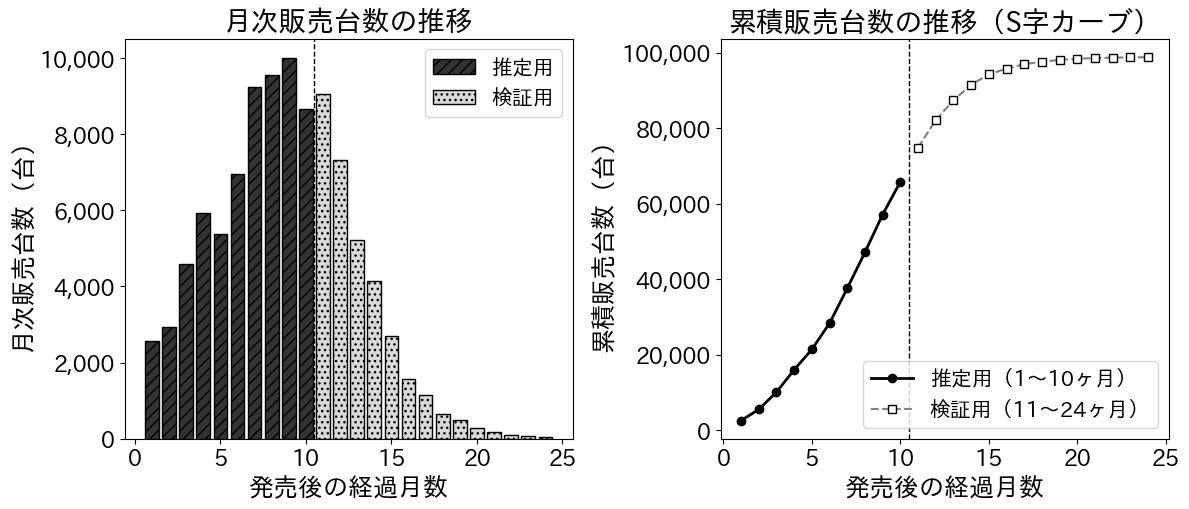

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))

# 各期間の販売台数（1〜10ヶ月：推定用、11〜24ヶ月：検証用）
axes[0].bar(
    df_observed["period"].to_list(),
    df_observed["n_sales"].to_list(),
    color=MONO_DARK,
    edgecolor=MONO_BLACK,
    hatch="///",
    label="推定用",
)
axes[0].bar(
    df_validation["period"].to_list(),
    df_validation["n_sales"].to_list(),
    color=MONO_LIGHT,
    edgecolor=MONO_BLACK,
    hatch="...",
    label="検証用",
)
axes[0].axvline(n_observed + 0.5, color=MONO_BLACK, linestyle="--", linewidth=1)
axes[0].set_xlabel("発売後の経過月数", fontsize=18)
axes[0].set_ylabel("月次販売台数（台）", fontsize=18)
axes[0].set_title("月次販売台数の推移", fontsize=20)
axes[0].yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{int(x):,}")
)
axes[0].legend(fontsize=15)

# 累積販売台数（S字）
axes[1].plot(
    df_observed["period"].to_list(),
    df_observed["N_cum"].to_list(),
    marker="o",
    color=MONO_BLACK,
    markerfacecolor=MONO_BLACK,
    linewidth=2,
    label="推定用（1〜10ヶ月）",
)
axes[1].plot(
    df_validation["period"].to_list(),
    df_validation["N_cum"].to_list(),
    marker="s",
    color=MONO_MID,
    markerfacecolor="white",
    markeredgecolor=MONO_BLACK,
    linewidth=1.5,
    linestyle="--",
    label="検証用（11〜24ヶ月）",
)
axes[1].axvline(n_observed + 0.5, color=MONO_BLACK, linestyle="--", linewidth=1)
axes[1].set_xlabel("発売後の経過月数", fontsize=18)
axes[1].set_ylabel("累積販売台数（台）", fontsize=18)
axes[1].set_title("累積販売台数の推移（S字カーブ）", fontsize=20)
axes[1].yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{int(x):,}")
)
axes[1].legend(fontsize=15)

for ax in axes:
    ax.tick_params(axis="both", labelsize=16)

plt.tight_layout()
plt.show()

## 第3章、第3節、第2項のコード

### バスモデルの関数の定義

離散時間版バスモデルを1期ずつ計算する関数と、条件を守りながら複数の初期値と重みを使って推定する関数を定義する。

#### 処理内容

1. **1期ずつ予測する関数の定義**
   `bass_model_sequence` は任意の累積採用者数 `N_start` から将来を予測する。`bass_model_predict` は発売後第1期から欠番なく並ぶ期番号だけを受け付け、引数が計算へ反映されない誤用を防ぐ。

2. **条件を満たすためのパラメータ変換**
   $p>0$、$q>0$、$p+q<1$、$M$が観測した累積販売台数を上回るという条件を `expit` と指数変換で常に満たす。各期で $0\leq n_t\leq M-N_{t-1}$ となることも確認する。

3. **安定して推定する関数の定義**
   複数の初期値を試し、初期値によって結果が変わる影響を抑える。重みは観測値ではなく、直前の予測値から作る。


In [6]:
def bass_model_sequence(
    n_periods: int, p: float, q: float, M: float, N_start: float = 0.0
) -> np.ndarray:
    """N_startからn_periods期分の新規採用者数を1期ずつ予測する。"""
    if not (p > 0 and q > 0 and p + q < 1 and M > 0):
        raise ValueError("p>0, q>0, p+q<1, M>0 が必要です。")
    if not (0 <= N_start < M):
        raise ValueError("N_start は0以上M未満である必要があります。")

    n_pred = np.zeros(n_periods, dtype=float)
    N_cum = float(N_start)
    for i in range(n_periods):
        adoption_prob = p + q * N_cum / M
        remaining = M - N_cum
        n_t = adoption_prob * remaining
        if not (0 <= adoption_prob <= 1 and -1e-8 <= n_t <= remaining + 1e-8):
            raise ValueError(
                "採用確率が0以上1以下になる条件を満たしていません。"
            )
        n_pred[i] = n_t
        N_cum += n_t
    return n_pred


def bass_model_predict(
    periods: np.ndarray, p: float, q: float, M: float
) -> np.ndarray:
    """発売後第1期から連続する各期の予測値を返す。"""
    periods_raw = np.asarray(periods)
    if (
        periods_raw.ndim != 1
        or not np.all(np.isfinite(periods_raw))
        or not np.all(periods_raw == periods_raw.astype(int))
    ):
        raise ValueError("periods は有限な整数の1次元配列にしてください。")
    periods = periods_raw.astype(int)
    expected = np.arange(1, len(periods) + 1)
    if not np.array_equal(periods, expected):
        raise ValueError("periods は1から欠番なく並べてください。")
    return bass_model_sequence(len(periods), p, q, M)


def unpack_theta(theta: np.ndarray, M_floor: float):
    """制約のないthetaを p>0, q>0, p+q<1, M>M_floor へ変換する。"""
    p = expit(theta[0])
    q = (1.0 - p) * expit(theta[1])
    M = M_floor + np.exp(theta[2])
    return p, q, M


def pack_theta(p: float, q: float, M: float, M_floor: float) -> np.ndarray:
    """p, q, Mを最適化用のthetaへ変換する。"""
    p = np.clip(p, 1e-6, 1 - 1e-6)
    q_share = np.clip(q / (1 - p), 1e-6, 1 - 1e-6)
    M_excess = max(M - M_floor, 1.0)
    return np.array([logit(p), logit(q_share), np.log(M_excess)])


def estimate_bass(
    periods: np.ndarray,
    n_sales_obs: np.ndarray,
    M_floor: float,
    initial_guesses: list[tuple],
):
    """複数の初期値と反復重み付けでp, q, Mを推定する。"""
    periods = np.asarray(periods, dtype=int)
    n_sales_obs = np.asarray(n_sales_obs, dtype=float)

    def transformed_model(x, theta_p, theta_q, theta_M):
        p, q, M = unpack_theta(np.array([theta_p, theta_q, theta_M]), M_floor)
        return bass_model_predict(x, p, q, M)

    theta_lower = [-12.0, -12.0, np.log(max(1.0, M_floor * 0.01))]
    theta_upper = [6.0, 6.0, np.log(max(1_000_000.0, M_floor * 100.0))]
    candidates = []

    for initial in initial_guesses:
        theta = pack_theta(*initial, M_floor=M_floor)
        sigma = np.ones_like(n_sales_obs)
        try:
            for _ in range(8):
                theta_prev = theta.copy()
                theta, _ = curve_fit(
                    transformed_model,
                    periods,
                    n_sales_obs,
                    p0=theta,
                    bounds=(theta_lower, theta_upper),
                    sigma=sigma,
                    absolute_sigma=False,
                    x_scale=[3.0, 3.0, 10.0],
                    max_nfev=10_000,
                )
                n_fit = transformed_model(periods, *theta)
                sigma = np.maximum(0.10 * n_fit, 1.0)
                if np.max(np.abs(theta - theta_prev)) < 1e-7:
                    break

            theta, pcov_theta = curve_fit(
                transformed_model,
                periods,
                n_sales_obs,
                p0=theta,
                bounds=(theta_lower, theta_upper),
                sigma=sigma,
                absolute_sigma=False,
                x_scale=[3.0, 3.0, 10.0],
                max_nfev=10_000,
            )
            n_fit = transformed_model(periods, *theta)
            objective = np.sum(((n_sales_obs - n_fit) / sigma) ** 2)
            candidates.append((objective, theta, pcov_theta, sigma, n_fit))
        except (RuntimeError, ValueError):
            continue

    if not candidates:
        raise RuntimeError("すべての初期値で推定に失敗しました。")

    objective, theta, pcov_theta, sigma, n_fit = min(
        candidates, key=lambda item: item[0]
    )
    p, q, M = unpack_theta(theta, M_floor)

    p_grad = p * (1 - p)
    q_share = expit(theta[1])
    transform_jac = np.array(
        [
            [p_grad, 0.0, 0.0],
            [-p_grad * q_share, (1 - p) * q_share * (1 - q_share), 0.0],
            [0.0, 0.0, M - M_floor],
        ]
    )
    pcov = transform_jac @ pcov_theta @ transform_jac.T
    perr = np.sqrt(np.maximum(np.diag(pcov), 0.0))

    return {
        "popt": np.array([p, q, M]),
        "perr": perr,
        "theta": theta,
        "pcov_theta": pcov_theta,
        "sigma": sigma,
        "n_fit": n_fit,
        "objective": objective,
    }

### 初期値とパラメータの範囲の設定

数値最適化を安定させるため、潜在市場規模の下限と複数の初期値を設定する。

#### 処理内容

1. **観測データの NumPy 配列への変換**
   `df_observed` から最初の10ヶ月の期番号と月次販売台数を NumPy 配列へ変換する。

2. **M の下限の設定**
   潜在市場規模は観測した累積販売台数より大きい必要があるため、その値を `M_floor` とする。

3. **複数の初期値の設定**
   $p$、$q$、$M$の異なる4組から計算を始め、重み付き残差平方和が最も小さい解を採用する。


In [7]:
# 最初の10ヶ月だけを推定用のNumPy配列に変換
periods_arr = df_observed["period"].to_numpy()
n_sales_arr = df_observed["n_sales"].to_numpy().astype(float)

# 潜在市場規模の下限と、結果を確かめるための複数の初期値
M_floor = float(df_observed["N_cum"].max())
initial_guesses = [
    (0.010, 0.20, M_floor * 1.5),
    (0.025, 0.35, M_floor * 2.0),
    (0.050, 0.50, M_floor * 4.0),
    (0.100, 0.20, M_floor * 8.0),
]

print(f"M の下限（観測した累積販売台数の最大値）: {M_floor:,.0f}")
print(f"試す初期値の数: {len(initial_guesses)}")

M の下限（観測した累積販売台数の最大値）: 65,814
試す初期値の数: 4


### パラメータの推定を実行

`estimate_bass` で $p$、$q$、$M$を推定し、推定値、標準誤差の概算、データを生成したときの設定値を表示する。

#### 処理内容

1. **重みを更新しながら推定**
   最初は各期の誤差の大きさを同じとみなし、以後は直前の予測値から `sigma = max(0.1 * n_fit, 1)` を更新する。観測値そのものを分母に使わないことで、小さく観測された期に過大な重みが付く問題を避ける。

2. **複数の初期値と値の大きさの調整**
   4組の初期値を試し、`x_scale` で変数の大きさの違いを調整する。`max_nfev=10_000` は計算回数の上限であり、必ず推定に成功することを保証するものではない。

3. **推定結果と条件の確認**
   推定値と標準誤差の概算を取り出し、$p+q<1$と、各期の予測値が残りの市場規模を超えないことを確認する。標準誤差は、将来の販売台数や事業上の判断に使う範囲を直接示すものではない。


In [8]:
fit_result = estimate_bass(periods_arr, n_sales_arr, M_floor, initial_guesses)
p_est, q_est, M_est = fit_result["popt"]
perr = fit_result["perr"]  # 標準誤差の概算
n_fit = fit_result["n_fit"]
probability_constraint_ok = p_est > 0 and q_est > 0 and p_est + q_est < 1

print("=" * 40)
print("推定結果")
print("=" * 40)
print(f"  p (外部影響係数) : {p_est:.4f}  (標準誤差の概算: {perr[0]:.4f})")
print(f"  q (内部影響係数) : {q_est:.4f}  (標準誤差の概算: {perr[1]:.4f})")
print(f"  M (潜在市場規模) : {M_est:,.0f}  (標準誤差の概算: {perr[2]:,.0f})")
print(
    f"  条件 p+q<1          : {probability_constraint_ok} (p+q={p_est + q_est:.4f})"
)
print()
print("データを生成したときの設定値との比較")
print(f"  p 設定値: {p_true:.4f} / 推定値: {p_est:.4f}")
print(f"  q 設定値: {q_true:.4f} / 推定値: {q_est:.4f}")
print(f"  M 設定値: {M_true:,}  / 推定値: {M_est:,.0f}")

推定結果
  p (外部影響係数) : 0.0255  (標準誤差の概算: 0.0025)
  q (内部影響係数) : 0.3335  (標準誤差の概算: 0.0366)
  M (潜在市場規模) : 98,515  (標準誤差の概算: 11,290)
  条件 p+q<1          : True (p+q=0.3591)

データを生成したときの設定値との比較
  p 設定値: 0.0250 / 推定値: 0.0255
  q 設定値: 0.3500 / 推定値: 0.3335
  M 設定値: 100,000  / 推定値: 98,515


### モデルの当てはまりの確認：決定係数 R²、予測値、残差

推定したパラメータによる予測値と実績値を比較し、$R^2$ と残差から推定期間内の当てはまりを確認する。$R^2$ に固定した合否基準は置かず、未使用期間の予測誤差やパラメータの安定性と合わせて判断する。

#### 処理内容

1. **R² の計算**
   残差平方和 RSS と全変動 TSS から $R^2 = 1 - \text{RSS}/\text{TSS}$ を算出する。

2. **実績値・予測値と残差のプロット**
   左図で実績値と予測値を重ね、右図で残差（実績値−予測値）の時間的な偏りを確認する。


R² = 0.9545


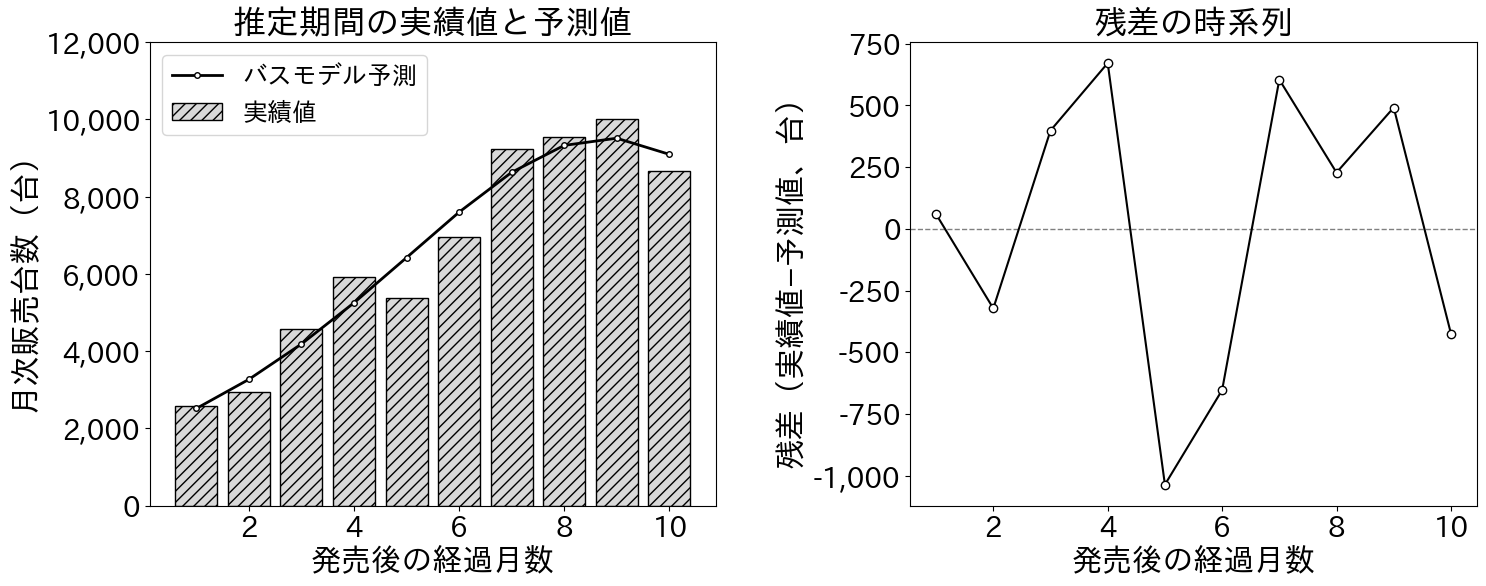

In [9]:
# 推定パラメータによる予測値
n_pred = n_fit.copy()

# 残差平方和と決定係数 R²
residuals = n_sales_arr - n_pred
rss = np.sum(residuals**2)
tss = np.sum((n_sales_arr - n_sales_arr.mean()) ** 2)
r2 = 1 - rss / tss
print(f"R² = {r2:.4f}")

# 左図：実績値と予測値
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].bar(
    periods_arr,
    n_sales_arr,
    color=MONO_LIGHT,
    edgecolor=MONO_BLACK,
    hatch="///",
    label="実績値",
)
axes[0].plot(
    periods_arr,
    n_pred,
    color=MONO_BLACK,
    linestyle="-",
    linewidth=2,
    marker="o",
    markersize=4,
    markerfacecolor="white",
    markeredgecolor=MONO_BLACK,
    label="バスモデル予測",
)
axes[0].set_xlabel("発売後の経過月数", fontsize=22)
axes[0].set_ylabel("月次販売台数（台）", fontsize=22)
axes[0].set_title("推定期間の実績値と予測値", fontsize=24)
axes[0].set_ylim(0, 12000)
axes[0].set_yticks(np.arange(0, 12001, 2000))
axes[0].yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{int(x):,}")
)
axes[0].legend(loc="upper left", fontsize=18)

# 右図：残差の時系列
axes[1].axhline(0, color=MONO_MID, linestyle="--", linewidth=1)
axes[1].plot(
    periods_arr,
    residuals,
    color=MONO_BLACK,
    linewidth=1.5,
    marker="o",
    markerfacecolor="white",
)
axes[1].set_xlabel("発売後の経過月数", fontsize=22)
axes[1].set_ylabel("残差（実績値−予測値、台）", fontsize=22)
axes[1].set_title("残差の時系列", fontsize=24)
axes[1].yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{int(x):,}")
)
for ax in axes:
    ax.tick_params(axis="both", labelsize=20)
plt.tight_layout(pad=1.2, w_pad=4.5)
plt.show()

## 第3章、第3節、第3項のコード

### 離散時間版を使った将来予測

推定した `p_est`、`q_est`、`M_est` を使い、10ヶ月時点の累積販売台数を出発点として48ヶ月目まで予測する。11〜24ヶ月を検証期間として扱い、未使用期間のMAEも計算する。

#### 処理内容

1. **推定期間と検証期間の設定**
   1〜10ヶ月を推定に使用し、11〜24ヶ月を推定時に見ていない検証期間として保持する。

2. **11〜48ヶ月の将来予測**
   `bass_model_sequence` の `N_start` に10ヶ月時点までに観測した累積販売台数を渡す。これにより、推定曲線上の累積値ではなく、実際に到達した状態から将来を予測する。

3. **10ヶ月時点の普及率と検証期間のMAEの確認**
   観測した累積販売台数が潜在市場規模の推定値 $M$ の何%に達しているかを表示し、11〜24ヶ月の月次の予測誤差の絶対値を平均する。


In [10]:
# 推定・検証・将来期間
t_obs = periods_arr.astype(int)  # 1〜10ヶ月
t_validation = df_validation["period"].to_numpy()  # 11〜24ヶ月
t_future = np.arange(n_observed + 1, 49, dtype=int)  # 11〜48ヶ月

# 10ヶ月時点の累積販売台数を出発点として48ヶ月目まで1期ずつ予測
observed_cum_10 = float(df_observed["N_cum"][-1])
n_pred_future = bass_model_sequence(
    len(t_future), p_est, q_est, M_est, N_start=observed_cum_10
)
N_pred_future = observed_cum_10 + np.cumsum(n_pred_future)
n_validation = df_validation["n_sales"].to_numpy().astype(float)
validation_pred = n_pred_future[: len(t_validation)]
validation_mae = np.mean(np.abs(n_validation - validation_pred))

print(f"潜在市場規模の推定値 (M_hat): {M_est:,.0f} 台")
print(f"推定期間末の累積販売台数 (10ヶ月): {observed_cum_10:,.0f} 台")
print(f"10ヶ月時点での普及率: {observed_cum_10 / M_est * 100:.1f}%")
print(f"検証期間のMAE (11〜24ヶ月): {validation_mae:,.0f} 台")

潜在市場規模の推定値 (M_hat): 98,515 台
推定期間末の累積販売台数 (10ヶ月): 65,814 台
10ヶ月時点での普及率: 66.8%
検証期間のMAE (11〜24ヶ月): 208 台


### 販売のピーク時点と、そのときの月次販売台数の算出

1〜10ヶ月の推定値と、10ヶ月時点の累積販売台数から計算した11〜48ヶ月の予測をつなぎ、販売のピークを迎える月と最大台数を計算する。

#### 処理内容

1. **ピーク時点 `t_peak` の計算**
   `np.argmax(n_pred_all)` で1〜48ヶ月の月次予測値が最大になる月を取得する。

2. **ピーク時の月次販売台数 `n_peak` の計算**
   ピーク時点での月次の販売台数の最大値を算出し、生産計画の参考値として出力する。


In [11]:
# 推定期間の予測値と、実績を起点とした将来予測をつないでピークを取得
t_all = np.concatenate([t_obs, t_future])
n_pred_all = np.concatenate([n_pred, n_pred_future])
peak_idx = int(np.argmax(n_pred_all))
t_peak = int(t_all[peak_idx])
n_peak = float(n_pred_all[peak_idx])

print(f"販売のピーク時点: {t_peak} ヶ月目")
print(f"ピーク時の月次販売台数: {n_peak:,.0f} 台")

販売のピーク時点: 9 ヶ月目
ピーク時の月次販売台数: 9,511 台


### S字カーブと将来予測の可視化

10ヶ月時点の累積販売台数を出発点とした予測と、11〜24ヶ月の検証期間の実績を横並びで描画する。予測を1つの値だけで示さず、パラメトリック・ブートストラップで得た予測結果の中央80%が入る範囲も示す。

#### 処理内容

1. **左図：月次販売台数（実績 + 予測）**
   推定用の実績、検証期間の実績、推定期間の当てはめ、実績を起点とした予測、予測範囲、ピーク時点、予測を始める時点を重ねる。初期の差を読みやすくするため、表示は30ヶ月目までとする。

2. **右図：累積販売台数（S字カーブ）**
   推定用の実績と検証期間の実績、実績を起点とした累積販売台数の予測とその範囲、予測を始める時点、潜在市場規模の推定値 $M$ を重ねる。予測範囲は仮定した誤差モデルに基づくものであり、価格改定・競合参入・欠品などモデル外の不確実性は含まない。


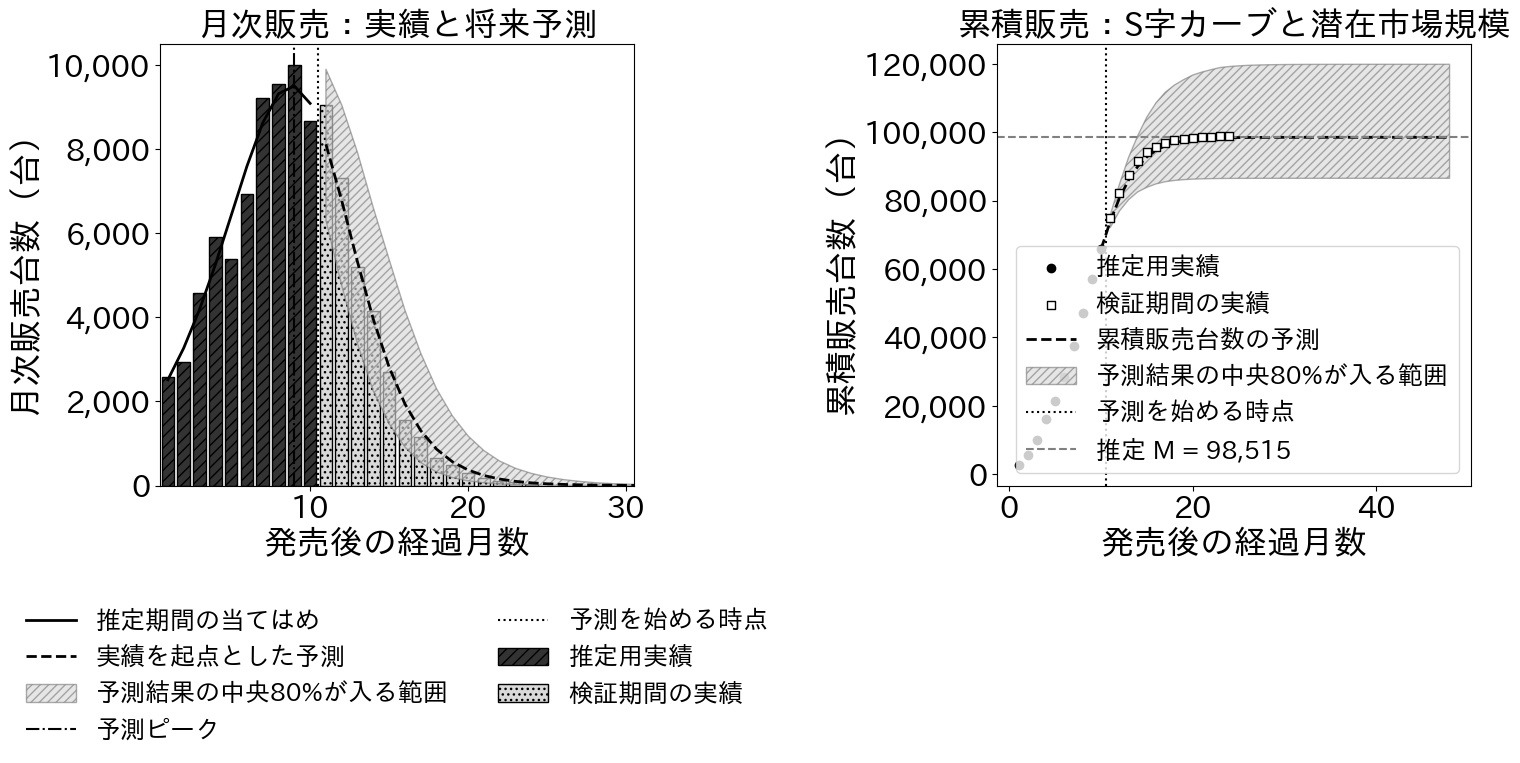

In [12]:
# 推定期間と検証期間の実績値
N_obs = df_observed["N_cum"].to_numpy().astype(float)
n_validation = df_validation["n_sales"].to_numpy().astype(float)
N_validation = df_validation["N_cum"].to_numpy().astype(float)

# パラメトリック・ブートストラップによる将来予測範囲
rng_boot = np.random.default_rng(123)
future_paths = []
for _ in range(200):
    n_boot = np.maximum(rng_boot.normal(n_pred, fit_result["sigma"]), 0.0)
    M_floor_boot = max(float(n_boot.sum()), float(observed_cum_10))
    M_start_boot = max(M_est, M_floor_boot * 1.05)
    try:
        fit_boot = estimate_bass(
            periods_arr,
            n_boot,
            M_floor=M_floor_boot,
            initial_guesses=[
                (p_est, q_est, M_start_boot),
                (0.025, 0.35, M_floor_boot * 2.0),
            ],
        )
        p_boot, q_boot, M_boot = fit_boot["popt"]
        if M_boot > observed_cum_10:
            future_paths.append(
                bass_model_sequence(
                    len(t_future),
                    p_boot,
                    q_boot,
                    M_boot,
                    N_start=observed_cum_10,
                )
            )
    except RuntimeError:
        continue

future_paths = np.asarray(future_paths)
if len(future_paths) < 100:
    raise RuntimeError("ブートストラップで推定に成功した回数が不足しています。")
n_future_lower, n_future_upper = np.quantile(future_paths, [0.10, 0.90], axis=0)
N_future_paths = observed_cum_10 + np.cumsum(future_paths, axis=1)
N_future_lower, N_future_upper = np.quantile(
    N_future_paths, [0.10, 0.90], axis=0
)

fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))

# --- 左図：各期間の販売台数（実績 + 予測）---
axes[0].bar(
    t_obs,
    n_sales_arr,
    color=MONO_DARK,
    edgecolor=MONO_BLACK,
    hatch="///",
    label="推定用実績",
)
axes[0].bar(
    t_validation,
    n_validation,
    color=MONO_LIGHT,
    edgecolor=MONO_BLACK,
    hatch="...",
    label="検証期間の実績",
)
axes[0].plot(
    t_obs,
    n_pred,
    color=MONO_BLACK,
    linestyle="-",
    linewidth=2,
    label="推定期間の当てはめ",
)
axes[0].plot(
    t_future,
    n_pred_future,
    color=MONO_BLACK,
    linestyle="--",
    linewidth=2,
    label="実績を起点とした予測",
)
axes[0].fill_between(
    t_future,
    n_future_lower,
    n_future_upper,
    color=MONO_LIGHT,
    alpha=0.65,
    hatch="////",
    edgecolor=MONO_MID,
    label="予測結果の中央80%が入る範囲",
)
axes[0].axvline(
    t_peak, color=MONO_BLACK, linestyle="-.", linewidth=1.5, label="予測ピーク"
)
axes[0].axvline(
    n_observed + 0.5,
    color=MONO_BLACK,
    linestyle=":",
    linewidth=1.5,
    label="予測を始める時点",
)
axes[0].set_xlabel("発売後の経過月数", fontsize=24)
axes[0].set_ylabel("月次販売台数（台）", fontsize=24)
axes[0].set_title("月次販売：実績と将来予測", fontsize=24)
axes[0].set_xlim(0.5, 30.5)
axes[0].yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{int(x):,}")
)
axes[0].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.23),
    ncol=2,
    fontsize=18,
    frameon=False,
)

# --- 右図：累積販売台数（S字カーブ）---
axes[1].scatter(
    t_obs, N_obs, marker="o", color=MONO_BLACK, zorder=5, label="推定用実績"
)
axes[1].scatter(
    t_validation,
    N_validation,
    marker="s",
    facecolors="white",
    edgecolors=MONO_BLACK,
    zorder=5,
    label="検証期間の実績",
)
t_forecast_line = np.concatenate([[n_observed], t_future])
N_forecast_line = np.concatenate([[observed_cum_10], N_pred_future])
axes[1].plot(
    t_forecast_line,
    N_forecast_line,
    color=MONO_BLACK,
    linestyle="--",
    linewidth=2,
    label="累積販売台数の予測",
)
axes[1].fill_between(
    t_future,
    N_future_lower,
    N_future_upper,
    color=MONO_LIGHT,
    alpha=0.65,
    hatch="////",
    edgecolor=MONO_MID,
    label="予測結果の中央80%が入る範囲",
)
axes[1].axvline(
    n_observed + 0.5,
    color=MONO_BLACK,
    linestyle=":",
    linewidth=1.5,
    label="予測を始める時点",
)
axes[1].axhline(
    M_est,
    color=MONO_MID,
    linestyle="--",
    linewidth=1.5,
    label=f"推定 M = {M_est:,.0f}",
)
axes[1].set_xlabel("発売後の経過月数", fontsize=24)
axes[1].set_ylabel("累積販売台数（台）", fontsize=24)
axes[1].set_title("累積販売：S字カーブと潜在市場規模", fontsize=24)
axes[1].yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{int(x):,}")
)
axes[1].legend(loc="lower right", fontsize=18)

for ax in axes:
    ax.tick_params(axis="both", labelsize=22)

plt.tight_layout(pad=1.4, w_pad=5.5)
plt.subplots_adjust(bottom=0.34)
plt.show()

### データ量を増やしたときの M の推定値の変化

使用するデータの期数を6から10まで1期ずつ増やしながら、本文と同じ条件で推定を繰り返し、潜在市場規模 $M$ の推定値がどのように変化するかを確認する。

#### 処理内容

1. **データの期数を増やしながら推定**
   `range(6, len(periods_arr) + 1)` のループで `estimate_bass` を繰り返し、推定した $M$ を記録する。推定に失敗した場合は `nan` とする。

2. **推定値の変化を描画**
   $M$の推定値の折れ線グラフに、データを生成したときの設定値を示す水平破線を重ね、どの段階で推定が安定するかを図で確認する。


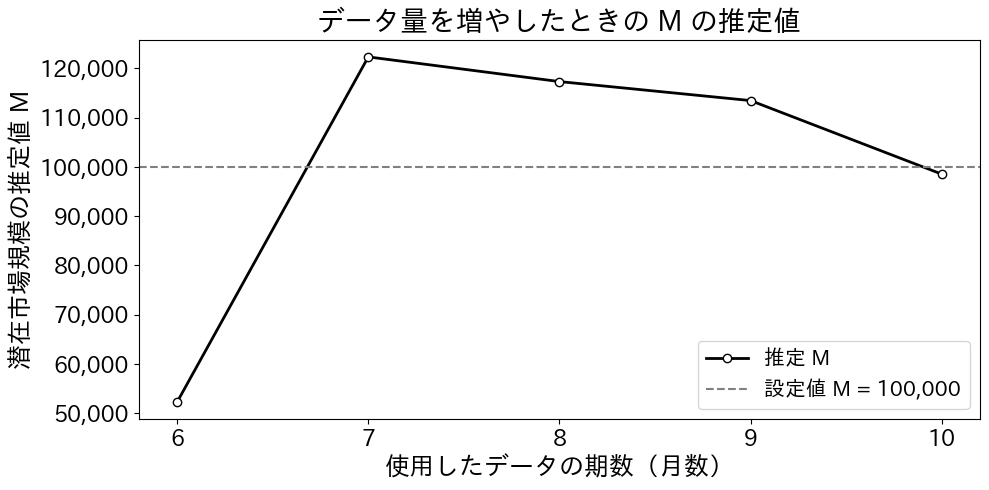

In [13]:
results = []
for n_obs in range(6, len(periods_arr) + 1):
    t_sub = periods_arr[:n_obs].astype(int)
    n_sub = n_sales_arr[:n_obs]
    M_floor_sub = float(n_sub.sum())
    initial_guesses_sub = [
        (0.005, 0.20, M_floor_sub * 1.5),
        (0.010, 0.30, M_floor_sub * 3.0),
        (0.030, 0.50, M_floor_sub * 6.0),
        (0.080, 0.70, M_floor_sub * 10.0),
    ]
    try:
        fit_sub = estimate_bass(t_sub, n_sub, M_floor_sub, initial_guesses_sub)
        popt_sub = fit_sub["popt"]
        results.append(
            {
                "n_obs": n_obs,
                "M_est": popt_sub[2],
                "p_est": popt_sub[0],
                "q_est": popt_sub[1],
            }
        )
    except RuntimeError:
        results.append(
            {
                "n_obs": n_obs,
                "M_est": float("nan"),
                "p_est": float("nan"),
                "q_est": float("nan"),
            }
        )

df_result = pl.DataFrame(results)

# データ量を増やしたときのMの推定値を描画
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    df_result["n_obs"].to_list(),
    df_result["M_est"].to_list(),
    marker="o",
    color=MONO_BLACK,
    markerfacecolor="white",
    linewidth=2,
    label="推定 M",
)
ax.axhline(
    M_true,
    color=MONO_MID,
    linestyle="--",
    linewidth=1.5,
    label=f"設定値 M = {M_true:,}",
)
ax.set_xlabel("使用したデータの期数（月数）", fontsize=18)
ax.set_ylabel("潜在市場規模の推定値 M", fontsize=18)
ax.set_title("データ量を増やしたときの M の推定値", fontsize=20)
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.tick_params(axis="both", labelsize=16)
ax.legend(fontsize=15)
plt.tight_layout()
plt.show()